# Material Dataset EDA

Exploratory analysis of composition, structure and property fields in DS-1. Each numbered chart is a separate figure.

**Data note:** these are supplied internship sample datasets. Figures describe the sample and should not be presented as verified live data.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("data/raw")
if not DATA.exists():
    DATA = Path("../data/raw")
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "figure.dpi": 110})
def finish(title, xlabel=None, ylabel=None):
    plt.title(title)
    if xlabel: plt.xlabel(xlabel)
    if ylabel: plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()
    plt.close()

df = pd.read_csv(DATA / "DS1_material_properties_5500.csv")
print(f"Rows: {len(df):,}; columns: {len(df.columns)}")
print(df.isna().mean().sort_values(ascending=False).head(10))

# 1. Crystal-system distribution


Rows: 5,500; columns: 18
material_id                     0.0
formula                         0.0
n_elements                      0.0
crystal_system                  0.0
spacegroup_number               0.0
category                        0.0
formation_energy_per_atom_eV    0.0
energy_above_hull_eV            0.0
band_gap_eV                     0.0
is_metal                        0.0
dtype: float64


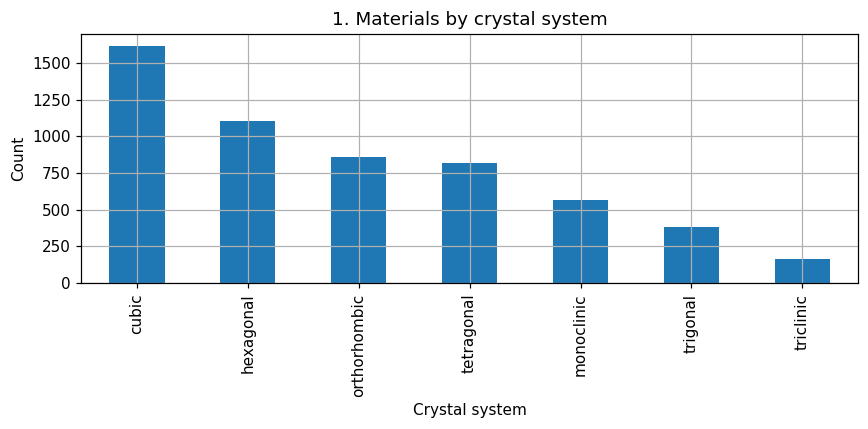

In [2]:
df["crystal_system"].value_counts().plot(kind="bar"); finish("1. Materials by crystal system", "Crystal system", "Count")

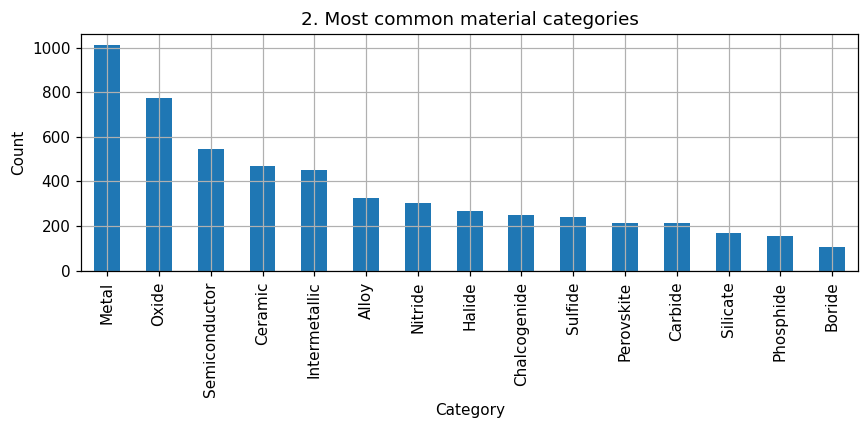

In [3]:
df["category"].value_counts().head(15).plot(kind="bar"); finish("2. Most common material categories", "Category", "Count")

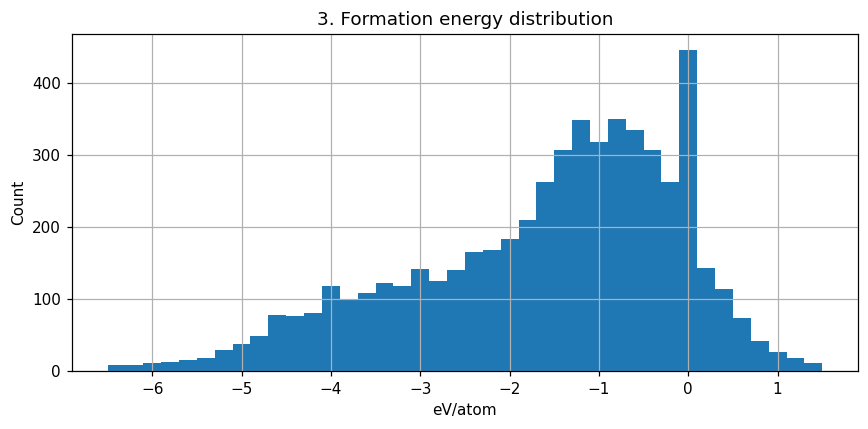

In [4]:
df["formation_energy_per_atom_eV"].hist(bins=40); finish("3. Formation energy distribution", "eV/atom", "Count")

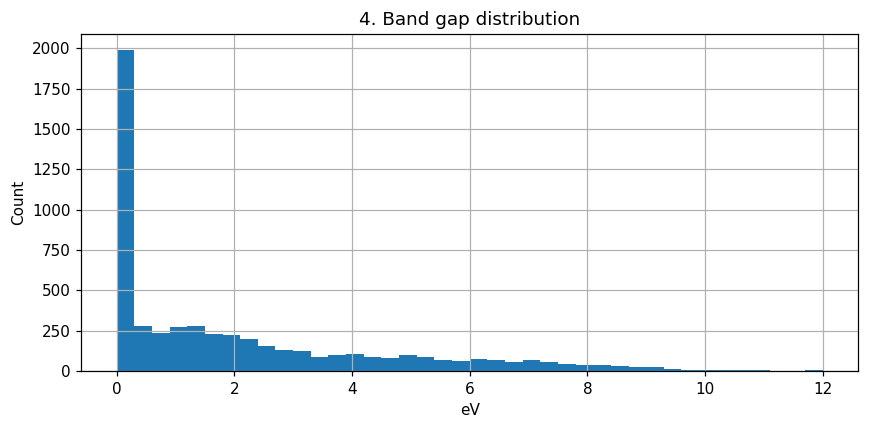

In [5]:
df["band_gap_eV"].hist(bins=40); finish("4. Band gap distribution", "eV", "Count")

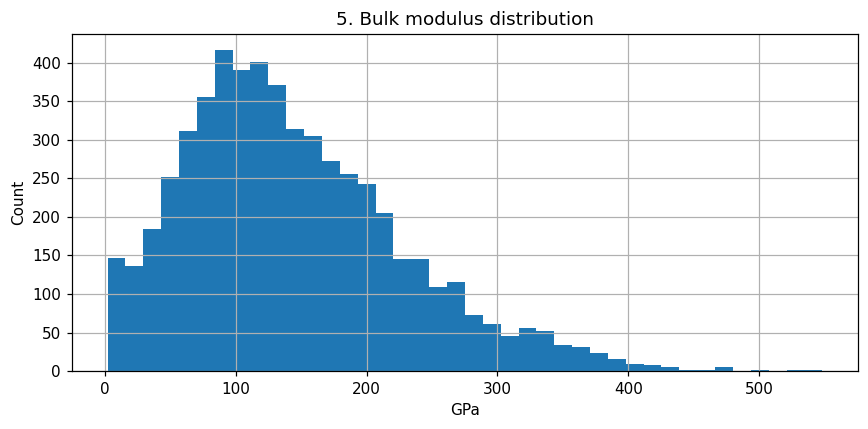

In [6]:
df["bulk_modulus_GPa"].hist(bins=40); finish("5. Bulk modulus distribution", "GPa", "Count")

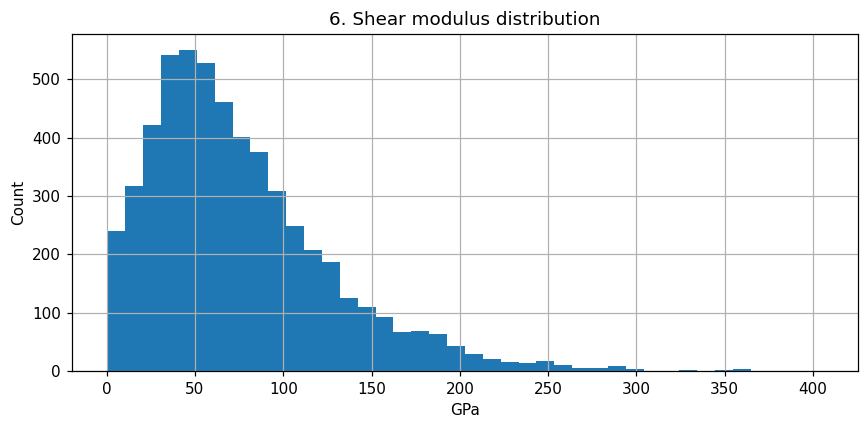

In [7]:
df["shear_modulus_GPa"].hist(bins=40); finish("6. Shear modulus distribution", "GPa", "Count")

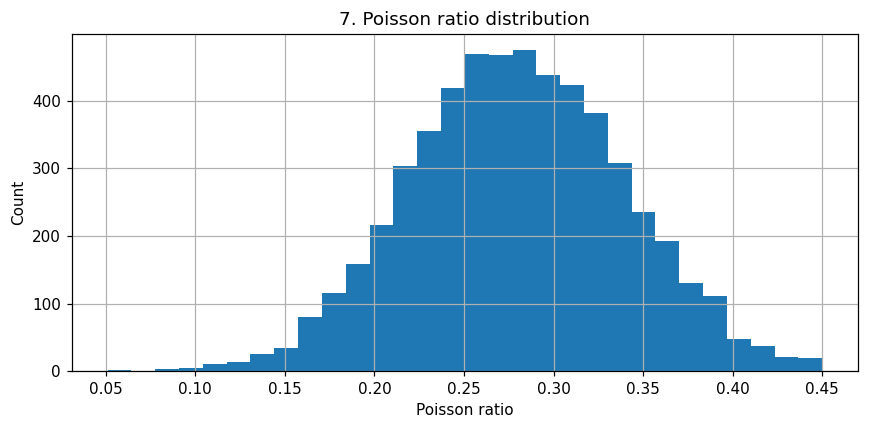

In [8]:
df["poisson_ratio"].hist(bins=30); finish("7. Poisson ratio distribution", "Poisson ratio", "Count")

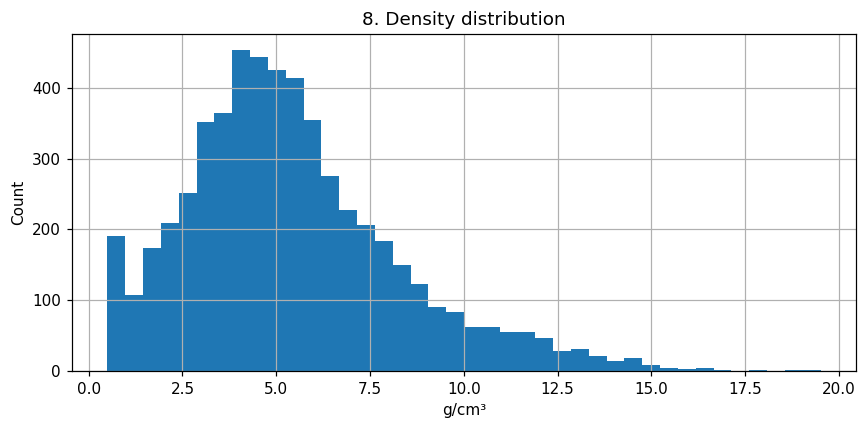

In [9]:
df["density_g_cm3"].hist(bins=40); finish("8. Density distribution", "g/cm³", "Count")

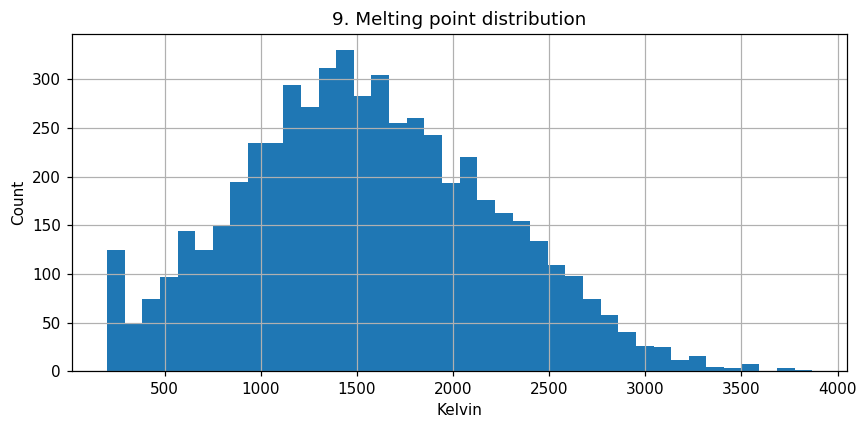

In [10]:
df["melting_point_K"].hist(bins=40); finish("9. Melting point distribution", "Kelvin", "Count")

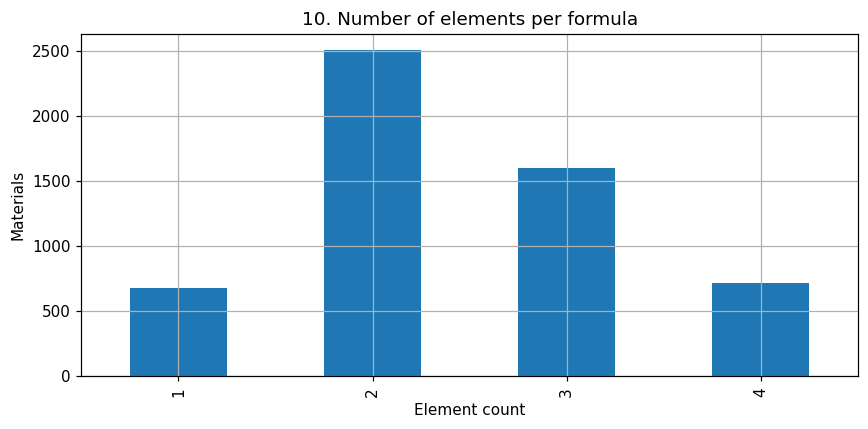

In [11]:
df["n_elements"].value_counts().sort_index().plot(kind="bar"); finish("10. Number of elements per formula", "Element count", "Materials")

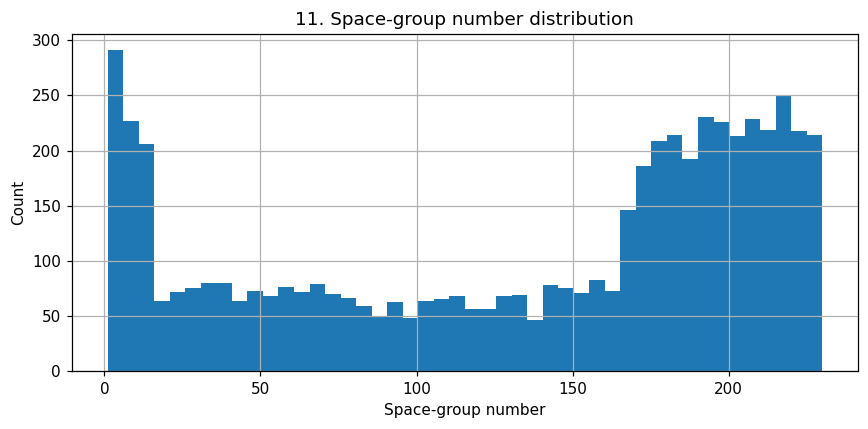

In [12]:
df["spacegroup_number"].hist(bins=46); finish("11. Space-group number distribution", "Space-group number", "Count")

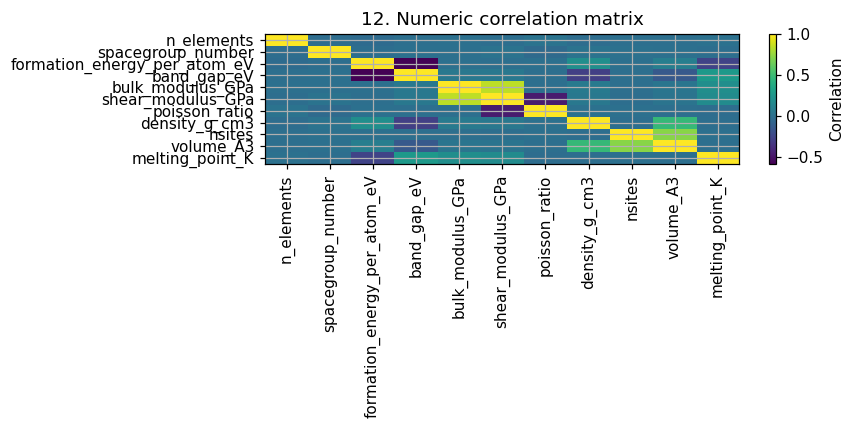

In [13]:
corr = df[["n_elements", "spacegroup_number", "formation_energy_per_atom_eV", "band_gap_eV", "bulk_modulus_GPa", "shear_modulus_GPa", "poisson_ratio", "density_g_cm3", "nsites", "volume_A3", "melting_point_K"]].corr(numeric_only=True); plt.imshow(corr, aspect="auto"); plt.xticks(range(len(corr)), corr.columns, rotation=90); plt.yticks(range(len(corr)), corr.columns); plt.colorbar(label="Correlation"); finish("12. Numeric correlation matrix")

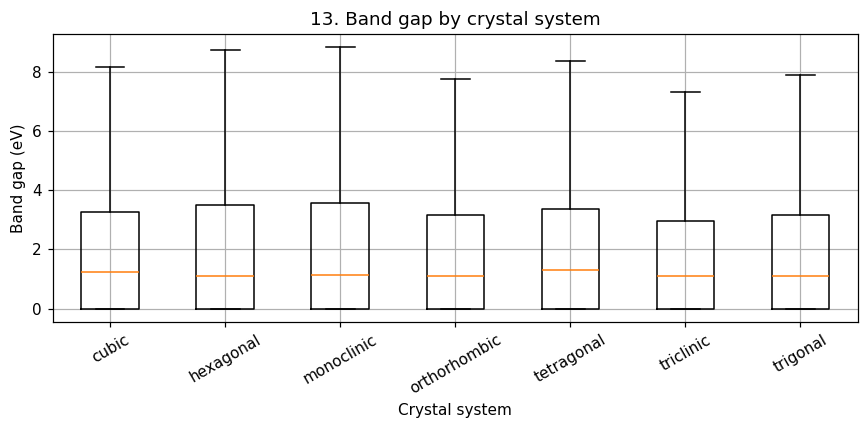

In [14]:
groups = [g["band_gap_eV"].dropna().values for _, g in df.groupby("crystal_system")]; labels = list(df.groupby("crystal_system").groups.keys()); plt.boxplot(groups, tick_labels=labels, showfliers=False); plt.xticks(rotation=30); finish("13. Band gap by crystal system", "Crystal system", "Band gap (eV)")

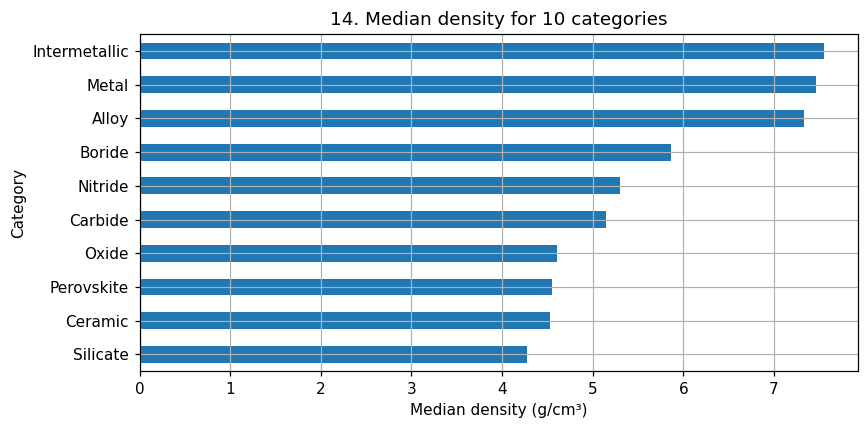

In [15]:
top = df.groupby("category")["density_g_cm3"].median().sort_values(ascending=False).head(10); top.sort_values().plot(kind="barh"); finish("14. Median density for 10 categories", "Median density (g/cm³)", "Category")

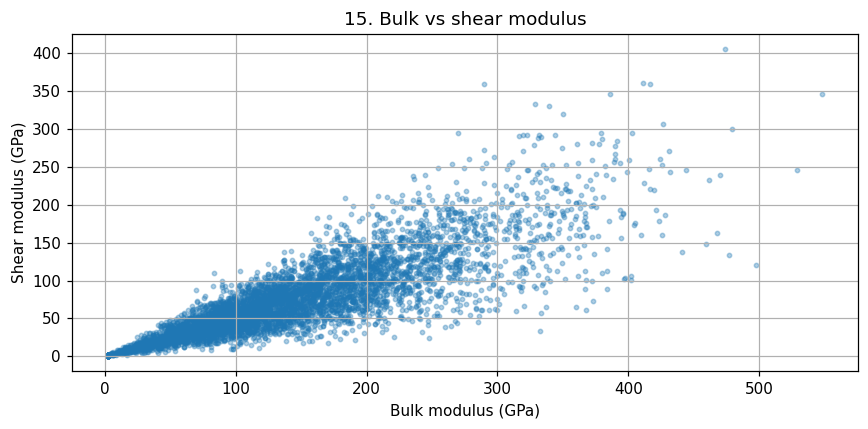

In [16]:
plt.scatter(df["bulk_modulus_GPa"], df["shear_modulus_GPa"], s=8, alpha=.35); finish("15. Bulk vs shear modulus", "Bulk modulus (GPa)", "Shear modulus (GPa)")

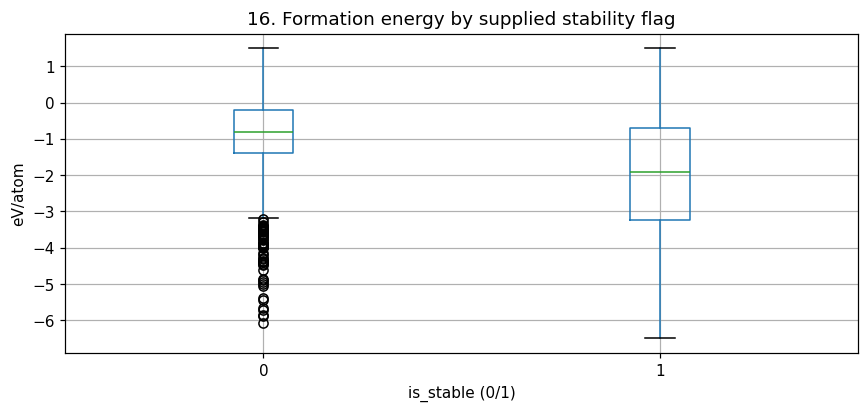

In [17]:
df.boxplot(column="formation_energy_per_atom_eV", by="is_stable", grid=True); plt.suptitle(""); finish("16. Formation energy by supplied stability flag", "is_stable (0/1)", "eV/atom")